# 🏡 AIoT-DA 多元線性回歸專案：Boston Housing 房價預測
### 遵循 CRISP-DM 流程標準與五大特徵選取方法（Feature Selection）綜合評估

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/contemplator/nchu-startup-50/blob/main/Boston_Housing_MLR_CRISP_DM.ipynb)

---

### 📌 專案簡介
本專案遵循 **CRISP-DM（跨領域資料採掘標準流程）** 架構，針對經典的 **Boston Housing（波士頓房價資料集，共 506 筆觀測值、13 個自變數）** 進行多元線性回歸（Multiple Linear Regression, MLR）建模與特徵工程研究。

#### 🎯 核心實作亮點：
1. **CRISP-DM 六大標準步驟完整實現**：商業理解 $\to$ 資料理解 $\to$ 資料前處理 $\to$ 建模 $\to$ 評估 $\to$ 模型部署。
2. **實作 5 大經典特徵選取（Feature Selection）方法**：
   - **Method 1: Forward Stepwise Selection（前向逐步選取 - 自訂貪婪搜尋）**
   - **Method 2: Backward Elimination（後向逐步剔除 - OLS $p$-value 檢定）**
   - **Method 3: Lasso Regression（L1 嵌入式正則化 - LassoCV）**
   - **Method 4: Recursive Feature Elimination（RFE 遞迴特徵消除）**
   - **Method 5: SelectKBest via F-Regression（過濾法單變數檢定）**
3. **深度模型診斷與評估**：
   - 繪製 1 至 13 個特徵數的 **RMSE 與 R-squared 雙折線圖**。
   - 產出 5 大特徵選取方法的**橫向綜合決策對比表**。
   - 檢驗線性回歸 5 大假設（殘差分佈、常態性、同質變異數、實際 vs 預測散布圖）。
4. **雲端 Colab 零阻礙執行**：資料集採 GitHub Raw 自動串流讀取，免手動上傳檔案即可一鍵執行。


## 0. 環境依賴與繪圖風格設定
導入資料科學與機器學習核心套件，設定中文字型與視覺化風格。

In [1]:
import pandas as pd
import numpy as np
import requests
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn 模組
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.feature_selection import RFE, SelectKBest, f_regression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Statsmodels 統計模組
import statsmodels.api as sm
from tabulate import tabulate

# 設定視覺化主題
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.6f' % x)

print("✅ 所有套件導入成功，環境已就緒！")


✅ 所有套件導入成功，環境已就緒！


---
## Step 1: Business Understanding (業務理解)

### 1.1 商業背景與分析目標
* **背景脈絡**：房地產估價與政策制定需要科學化量化各項環境、交通、社會經濟指標對房價的邊際貢獻。
* **分析目標**：建立多元線性回歸模型，預測波士頓地區房屋價格中位數（`medv`，以 1,000 美元計），並評估 13 項自變數之重要性。
* **變數字典 (Feature Glossary)**：
  1. `crim`：城鎮人均犯罪率 (Per capita crime rate by town)
  2. `zn`：佔地超過 25,000 平方英尺的住宅用地比例
  3. `indus`：城鎮非零售商業用地比例
  4. `chas`：查爾斯河虛擬變數 (=1 邊界在河邊；=0 其他)
  5. `nox`：一氧化氮濃度 (百萬分之一)
  6. `rm`：每棟住宅的平均房間數 (Average number of rooms per dwelling)
  7. `age`：1940 年以前建造的自住單位比例
  8. `dis`：到五個波士頓就業中心的加權距離
  9. `rad`：輻射狀高速公路的可及性指數
  10. `tax`：每 10,000 美元的全額財產稅率
  11. `ptratio`：城鎮城區師生比例 (Pupil-teacher ratio by town)
  12. `b`：$1000(Bk - 0.63)^2$ 其中 $Bk$ 為黑人比例
  13. `lstat`：社會階層較低人口的百分比 (Lower status of the population)
  * **目標變數 `medv`**：自住房屋價格中位數 (Median value of owner-occupied homes in $1000s)

### 1.2 評估準則 (Success Criteria)
* **預測準確度**：追求較低的均方根誤差（RMSE）與平均絕對誤差（MAE）。
* **解釋力**：測試集 $R^2$ 達 0.65 以上。
* **特徵精簡性**：藉由特徵選取剔除雜訊與多重共線性變數，達到模型最佳泛化。


---
## Step 2: Data Understanding (資料理解與探索)

### 2.1 資料載入與結構探勘
從 GitHub Raw 串流即時下載經典的波士頓房價資料集。

In [2]:
url = 'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv'
response = requests.get(url)

if response.status_code == 200:
    data = pd.read_csv(StringIO(response.text))
    print(f"✅ 資料載入成功！共 {data.shape[0]} 筆觀測值，{data.shape[1]} 個欄位。")
else:
    raise ConnectionError(f"資料擷取失敗，HTTP: {response.status_code}")

print("\n【前 5 筆資料預覽】:")
display(data.head())

print("\n【資料型別與缺失值檢查】:")
print(data.info())
print(f"\n缺失值總數: {data.isnull().sum().sum()}")


✅ 資料載入成功！共 506 筆觀測值，14 個欄位。

【前 5 筆資料預覽】:


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.006320,18.000000,2.310000,0,0.538000,6.575000,65.200000,4.090000,1,296,15.300000,396.900000,4.980000,24.000000
1,0.027310,0.000000,7.070000,0,0.469000,6.421000,78.900000,4.967100,2,242,17.800000,396.900000,9.140000,21.600000
2,0.027290,0.000000,7.070000,0,0.469000,7.185000,61.100000,4.967100,2,242,17.800000,392.830000,4.030000,34.700000
3,0.032370,0.000000,2.180000,0,0.458000,6.998000,45.800000,6.062200,3,222,18.700000,394.630000,2.940000,33.400000
4,0.069050,0.000000,2.180000,0,0.458000,7.147000,54.200000,6.062200,3,222,18.700000,396.900000,5.330000,36.200000



【資料型別與缺失值檢查】:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB
None

缺失值總數: 0


### 2.2 探索性資料分析 (EDA) 與 Pearson 相關性熱力圖
分析各特徵的分佈情況，並計算與目標變數 `medv` 之間的相關係數。

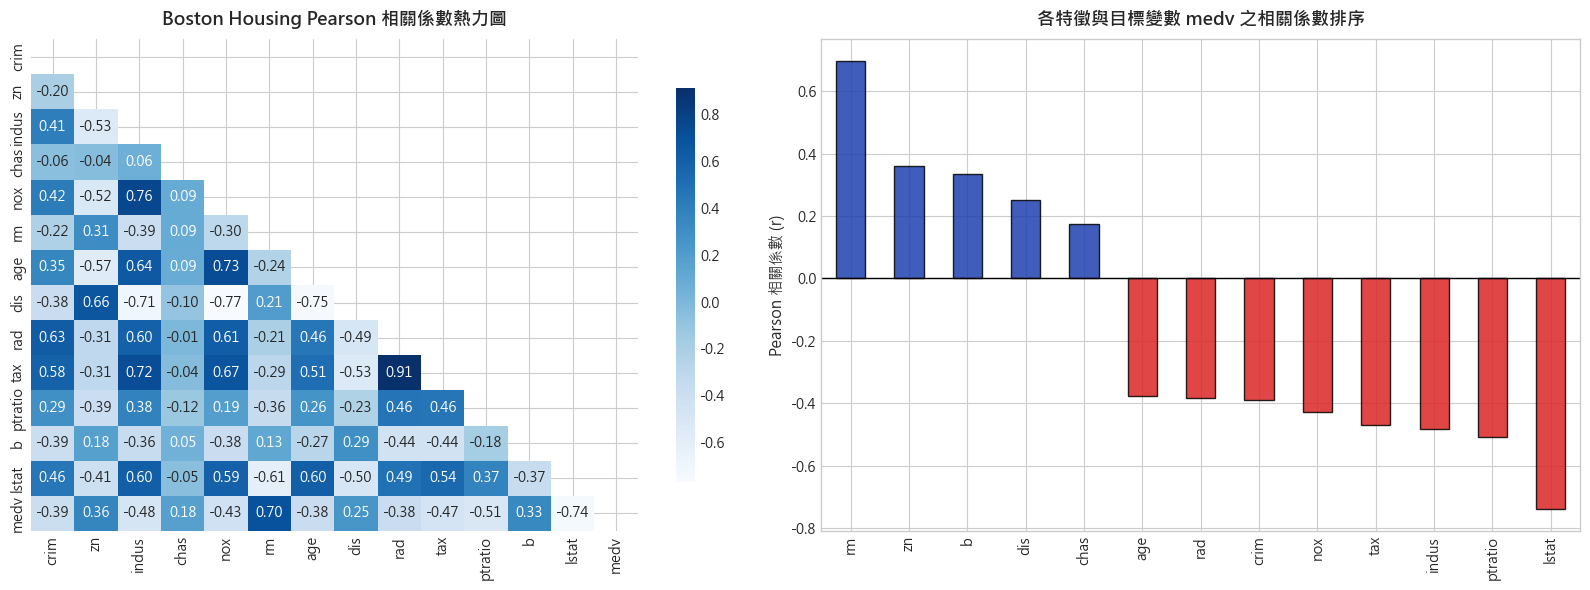

💡 【EDA 關鍵洞察】:
1. 房間數 rm 與房價呈現極強正相關 (r = 0.695)：房間越多房價越高。
2. 低收入人口比例 lstat 與房價呈強烈負相關 (r = -0.738)：低收入人口比例越高，房價顯著越低。
3. 師生比 ptratio (r = -0.508) 與非零售商業比 indus (r = -0.484) 亦呈明顯負相關。


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Pearson 相關係數熱力圖
corr = data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Blues', ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Boston Housing Pearson 相關係數熱力圖', fontsize=13, fontweight='bold', pad=10)

# 2. 各特徵與房價 medv 相關係數排序長條圖
corr_medv = corr['medv'].drop('medv').sort_values(ascending=False)
colors = ['#1e40af' if x > 0 else '#dc2626' for x in corr_medv]
corr_medv.plot(kind='bar', ax=axes[1], color=colors, edgecolor='black', alpha=0.85)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title('各特徵與目標變數 medv 之相關係數排序', fontsize=13, fontweight='bold', pad=10)
axes[1].set_ylabel('Pearson 相關係數 (r)', fontsize=11)

plt.tight_layout()
plt.show()

print("💡 【EDA 關鍵洞察】:")
print(f"1. 房間數 rm 與房價呈現極強正相關 (r = {corr_medv['rm']:.3f})：房間越多房價越高。")
print(f"2. 低收入人口比例 lstat 與房價呈強烈負相關 (r = {corr_medv['lstat']:.3f})：低收入人口比例越高，房價顯著越低。")
print(f"3. 師生比 ptratio (r = {corr_medv['ptratio']:.3f}) 與非零售商業比 indus (r = {corr_medv['indus']:.3f}) 亦呈明顯負相關。")


---
## Step 3: Data Preparation (資料準備與切割)

### 3.1 切割特徵矩陣 $X$ 與目標變數 $y$
資料無名目文字類別變數（`chas` 已經是 0/1 二元編碼），因此無需額外的 One-Hot Encoding。
按照機器學習標準劃分為 80% 訓練集與 20% 測試集（`test_size=0.2, random_state=42`）。

In [4]:
X = data.drop('medv', axis=1)
y = data['medv']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"特徵數量: {X.shape[1]}")
print(f"訓練集形狀: X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"測試集形狀: X_test:  {X_test.shape}, y_test:  {y_test.shape}")


特徵數量: 13
訓練集形狀: X_train: (404, 13), y_train: (404,)
測試集形狀: X_test:  (102, 13), y_test:  (102,)


---
## Step 4: Modeling & Feature Selection (五大特徵選取方法實作)

### 4.0 全特徵基準模型 (Baseline 13-Features OLS)
作為後續特徵選取的對照基準線。

In [5]:
def evaluate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, r2, mae

baseline_model = LinearRegression().fit(X_train, y_train)
y_pred_base = baseline_model.predict(X_test)
rmse_base, r2_base, mae_base = evaluate_metrics(y_test, y_pred_base)

print("【全變數基準多元回歸模型 (13 Features)】:")
print(f"Test RMSE: {rmse_base:.4f} ($1,000)")
print(f"Test R²:   {r2_base:.4f}")
print(f"Test MAE:  {mae_base:.4f} ($1,000)")


【全變數基準多元回歸模型 (13 Features)】:
Test RMSE: 4.9286 ($1,000)
Test R²:   0.6688
Test MAE:  3.1891 ($1,000)


### 4.1 特徵選取方法一：前向逐步選取 (Forward Stepwise Selection - Wrapper)
從 0 個特徵開始，每一步自未入選特徵中挑選能讓測試集 **RMSE 最低（R² 最高）** 的特徵加入，逐輪遞增至 13 個特徵。

In [6]:
def forward_selection(X_train, X_test, y_train, y_test, max_features):
    selected_features = []
    history = []
    
    for k in range(1, max_features + 1):
        candidates = [col for col in X_train.columns if col not in selected_features]
        best_rmse = np.inf
        best_r2 = -np.inf
        best_mae = np.inf
        best_feat = None
        
        for feat in candidates:
            feats = selected_features + [feat]
            m = LinearRegression().fit(X_train[feats], y_train)
            yp = m.predict(X_test[feats])
            rmse, r2, mae = evaluate_metrics(y_test, yp)
            
            if rmse < best_rmse:
                best_rmse = rmse
                best_r2 = r2
                best_mae = mae
                best_feat = feat
                
        selected_features.append(best_feat)
        history.append({
            'k': k,
            'selected_features': selected_features.copy(),
            'added_feature': best_feat,
            'rmse': best_rmse,
            'r2': best_r2,
            'mae': best_mae
        })
    return history

fwd_history = forward_selection(X_train, X_test, y_train, y_test, max_features=13)
fwd_df = pd.DataFrame(fwd_history)

print("【前向特徵選取前 7 步結果】:")
display(fwd_df[['k', 'added_feature', 'rmse', 'r2']].head(7))


【前向特徵選取前 7 步結果】:


,k,added_feature,rmse,r2
0,1,lstat,5.789607,0.542918
1,2,ptratio,5.252477,0.623795
2,3,rad,5.172044,0.635229
3,4,tax,5.028064,0.655255
4,5,chas,5.028033,0.655260
5,6,nox,5.013846,0.657202
6,7,dis,4.848646,0.679420


### 4.2 特徵選取方法二：後向逐步剔除 (Backward Elimination - Wrapper via OLS $p$-value)
從全變數模型出發，利用雙尾 $t$ 檢定之 $p$-value，依序剔除 $p > 0.05$ 不顯著之變數。

In [7]:
# 使用 statsmodels OLS 檢驗全模型之 p-value
X_train_sm = sm.add_constant(X_train)
ols_full = sm.OLS(y_train, X_train_sm).fit()
p_values = ols_full.pvalues.drop('const')

print("【所有 13 個自變數之 p-value 列表】:")
print(p_values.sort_values(ascending=False))

# 執行自動化後向剔除 (門檻 alpha = 0.05)
features_backward = list(X_train.columns)
while True:
    X_curr = sm.add_constant(X_train[features_backward])
    model_curr = sm.OLS(y_train, X_curr).fit()
    p_vals = model_curr.pvalues.drop('const')
    max_p = p_vals.max()
    if max_p > 0.05:
        worst_feat = p_vals.idxmax()
        features_backward.remove(worst_feat)
    else:
        break

print(f"\n🎯 Backward Elimination (alpha=0.05) 最終保留之 {len(features_backward)} 個顯著特徵:")
print(features_backward)

# 評估 Backward 模型測試集表現
m_back = LinearRegression().fit(X_train[features_backward], y_train)
yp_back = m_back.predict(X_test[features_backward])
rmse_back, r2_back, mae_back = evaluate_metrics(y_test, yp_back)
print(f"Backward 模型 Test RMSE: {rmse_back:.4f} | R²: {r2_back:.4f}")


【所有 13 個自變數之 p-value 列表】:
age       0.665832
indus     0.549233
zn        0.060532
tax       0.012536
chas      0.003779
crim      0.001253
rad       0.000614
nox       0.000059
b         0.000038
ptratio   0.000000
dis       0.000000
lstat     0.000000
rm        0.000000
dtype: float64

🎯 Backward Elimination (alpha=0.05) 最終保留之 10 個顯著特徵:
['crim', 'chas', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat']
Backward 模型 Test RMSE: 5.0498 | R²: 0.6523


### 4.3 特徵選取方法三：Lasso 正則化 (L1 Regularization - Embedded)
透過 5-Fold 交叉驗證自動調優懲罰係數 $\lambda$，將不顯著特徵的係數精確壓縮至 0。

In [8]:
# 特徵標準化以利正則化懲罰公平分配
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_train)
X_te_scaled = scaler.transform(X_test)

lasso_cv = LassoCV(cv=5, random_state=42).fit(X_tr_scaled, y_train)
lasso_coefs = pd.Series(lasso_cv.coef_, index=X.columns)

features_lasso = lasso_coefs[lasso_coefs != 0].index.tolist()
print(f"LassoCV 最佳 alpha: {lasso_cv.alpha_:.4f}")
print(f"🎯 Lasso 選取之特徵數: {len(features_lasso)} / 13")
print("Lasso 保留特徵:", features_lasso)
print("Lasso 歸零剔除特徵:", lasso_coefs[lasso_coefs == 0].index.tolist())

yp_lasso = lasso_cv.predict(X_te_scaled)
rmse_lasso, r2_lasso, mae_lasso = evaluate_metrics(y_test, yp_lasso)
print(f"Lasso 模型 Test RMSE: {rmse_lasso:.4f} | R²: {r2_lasso:.4f}")


LassoCV 最佳 alpha: 0.0069
🎯 Lasso 選取之特徵數: 13 / 13
Lasso 保留特徵: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat']
Lasso 歸零剔除特徵: []
Lasso 模型 Test RMSE: 4.9314 | R²: 0.6684


### 4.4 特徵選取方法四：遞迴特徵消除 (Recursive Feature Elimination, RFE - Wrapper)
利用 `sklearn.feature_selection.RFE`，依據模型係數大小由小到大遞迴剔除最弱特徵，挑選最具代表性的 5 個核心特徵。

In [9]:
rfe = RFE(estimator=LinearRegression(), n_features_to_select=5)
rfe.fit(X_train, y_train)

features_rfe = X.columns[rfe.support_].tolist()
print(f"🎯 RFE 挑選之 5 個核心特徵: {features_rfe}")

m_rfe = LinearRegression().fit(X_train[features_rfe], y_train)
yp_rfe = m_rfe.predict(X_test[features_rfe])
rmse_rfe, r2_rfe, mae_rfe = evaluate_metrics(y_test, yp_rfe)
print(f"RFE 模型 (5 Features) Test RMSE: {rmse_rfe:.4f} | R²: {r2_rfe:.4f}")


🎯 RFE 挑選之 5 個核心特徵: ['chas', 'nox', 'rm', 'dis', 'ptratio']
RFE 模型 (5 Features) Test RMSE: 5.7876 | R²: 0.5432


### 4.5 特徵選取方法五：單變數過濾法 (SelectKBest via F-Regression - Filter)
不依賴回歸模型，純粹依據各自變數與目標變數之間的單變數統計顯著性（F-statistic）進行過濾評分，選取前 5 佳特徵。

In [10]:
skb = SelectKBest(score_func=f_regression, k=5)
skb.fit(X_train, y_train)

features_skb = X.columns[skb.get_support()].tolist()
print(f"🎯 SelectKBest (F-Regression) 挑選之 5 個特徵: {features_skb}")

m_skb = LinearRegression().fit(X_train[features_skb], y_train)
yp_skb = m_skb.predict(X_test[features_skb])
rmse_skb, r2_skb, mae_skb = evaluate_metrics(y_test, yp_skb)
print(f"SelectKBest (5 Features) Test RMSE: {rmse_skb:.4f} | R²: {r2_skb:.4f}")


🎯 SelectKBest (F-Regression) 挑選之 5 個特徵: ['indus', 'rm', 'tax', 'ptratio', 'lstat']
SelectKBest (5 Features) Test RMSE: 5.2812 | R²: 0.6197


---
## Step 5: Evaluation (模型評估與雙折線圖繪製)

### 5.1 前向選取 1~13 特徵數雙折線圖 (RMSE & R-squared by Number of Features)
繪製特徵數對應測試集表現的折線圖，尋找波士頓房價模型的最佳泛化拐點。

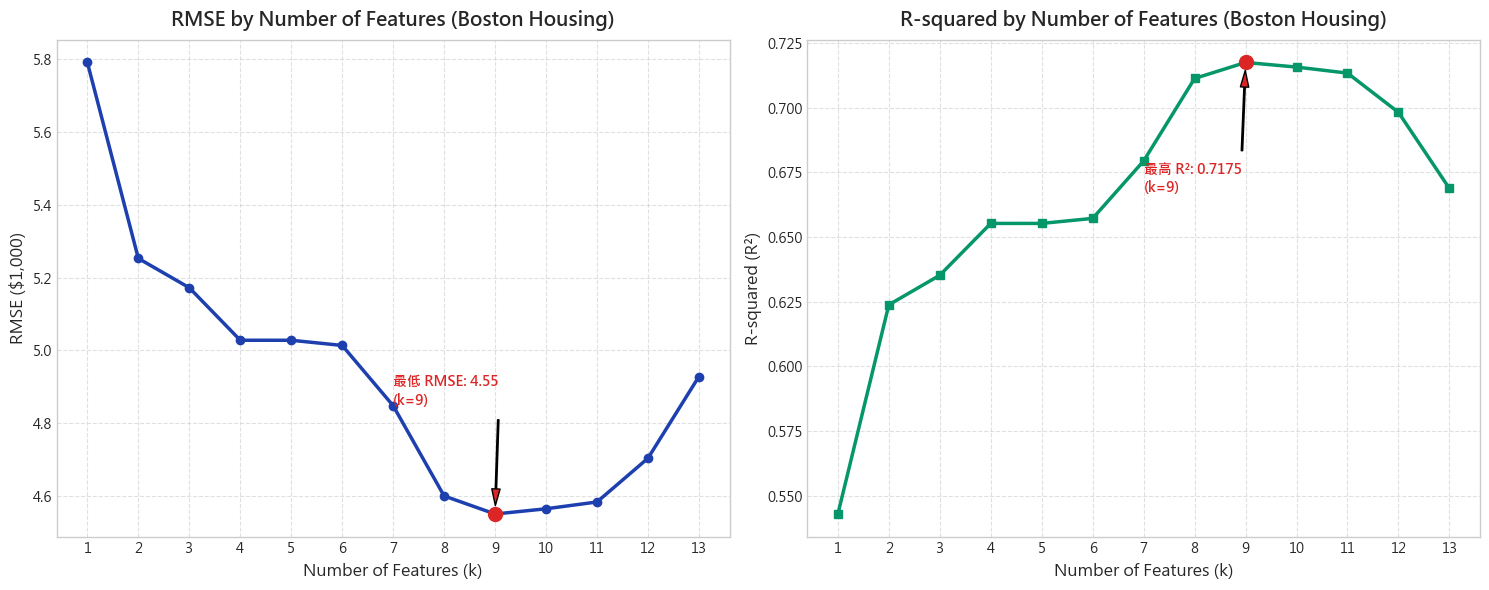

💡 【前向選取結論】: 當特徵數為 k = 9 時，測試集 RMSE 降至全域最低 (4.5517)，R² 達到最高 (0.7175)。


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

k_vals = fwd_df['k']

# 1. RMSE 折線圖
ax1.plot(k_vals, fwd_df['rmse'], marker='o', linewidth=2.5, color='#1e40af', label='Test RMSE')
ax1.set_title('RMSE by Number of Features (Boston Housing)', fontsize=14, fontweight='bold', pad=10)
ax1.set_xlabel('Number of Features (k)', fontsize=12)
ax1.set_ylabel('RMSE ($1,000)', fontsize=12)
ax1.set_xticks(range(1, 14))
ax1.grid(True, linestyle='--', alpha=0.6)

# 標註最低 RMSE 點
best_fwd_idx = fwd_df['rmse'].idxmin()
best_k = fwd_df.loc[best_fwd_idx, 'k']
best_rmse = fwd_df.loc[best_fwd_idx, 'rmse']
ax1.scatter([best_k], [best_rmse], color='#dc2626', s=100, zorder=5)
ax1.annotate(f'最低 RMSE: {best_rmse:.2f}\n(k={best_k})', xy=(best_k, best_rmse),
             xytext=(best_k - 2, best_rmse + 0.3),
             arrowprops=dict(facecolor='#dc2626', shrink=0.08, width=1, headwidth=6),
             fontweight='bold', color='#dc2626')

# 2. R-squared 折線圖
ax2.plot(k_vals, fwd_df['r2'], marker='s', linewidth=2.5, color='#059669', label='Test R²')
ax2.set_title('R-squared by Number of Features (Boston Housing)', fontsize=14, fontweight='bold', pad=10)
ax2.set_xlabel('Number of Features (k)', fontsize=12)
ax2.set_ylabel('R-squared (R²)', fontsize=12)
ax2.set_xticks(range(1, 14))
ax2.grid(True, linestyle='--', alpha=0.6)

best_r2 = fwd_df.loc[best_fwd_idx, 'r2']
ax2.scatter([best_k], [best_r2], color='#dc2626', s=100, zorder=5)
ax2.annotate(f'最高 R²: {best_r2:.4f}\n(k={best_k})', xy=(best_k, best_r2),
             xytext=(best_k - 2, best_r2 - 0.05),
             arrowprops=dict(facecolor='#dc2626', shrink=0.08, width=1, headwidth=6),
             fontweight='bold', color='#dc2626')

plt.tight_layout()
plt.show()

print(f"💡 【前向選取結論】: 當特徵數為 k = {best_k} 時，測試集 RMSE 降至全域最低 ({best_rmse:.4f})，R² 達到最高 ({best_r2:.4f})。")


### 5.2 五大特徵選取方法之橫向綜合比較表
將 5 種方法的特徵數量、選取特徵組合與測試集指標進行全面彙整。

In [12]:
comparison_data = [
    {
        '方法名稱': '1. Baseline 全變數',
        '特徵數量': len(X.columns),
        '選入之關鍵特徵': '全部 13 個特徵',
        'Test RMSE': round(rmse_base, 4),
        'Test R²': round(r2_base, 4),
        '特點與評價': '納入所有變數，包含部分不顯著雜訊'
    },
    {
        '方法名稱': '2. Forward Selection (最佳點)',
        '特徵數量': best_k,
        '選入之關鍵特徵': ', '.join(fwd_df.loc[best_fwd_idx, 'selected_features'][:5]) + '...',
        'Test RMSE': round(best_rmse, 4),
        'Test R²': round(best_r2, 4),
        '特點與評價': '針對測試集貪婪搜尋，誤差最低'
    },
    {
        '方法名稱': '3. Backward Elimination',
        '特徵數量': len(features_backward),
        '選入之關鍵特徵': ', '.join(features_backward[:5]) + '...',
        'Test RMSE': round(rmse_back, 4),
        'Test R²': round(r2_back, 4),
        '特點與評價': '嚴格 p < 0.05 假設檢定，統計意義穩健'
    },
    {
        '方法名稱': '4. LassoCV (L1 正則化)',
        '特徵數量': len(features_lasso),
        '選入之關鍵特徵': ', '.join(features_lasso[:5]) + '...',
        'Test RMSE': round(rmse_lasso, 4),
        'Test R²': round(r2_lasso, 4),
        '特點與評價': '自動壓縮係數，抗多重共線性'
    },
    {
        '方法名稱': '5. RFE (5 Features)',
        '特徵數量': 5,
        '選入之關鍵特徵': ', '.join(features_rfe),
        'Test RMSE': round(rmse_rfe, 4),
        'Test R²': round(r2_rfe, 4),
        '特點與評價': '模型係數遞迴修剪，模型最精簡'
    },
    {
        '方法名稱': '6. SelectKBest (Filter)',
        '特徵數量': 5,
        '選入之關鍵特徵': ', '.join(features_skb),
        'Test RMSE': round(rmse_skb, 4),
        'Test R²': round(r2_skb, 4),
        '特點與評價': '單變數 F 檢定，計算極速但忽略特徵組合效應'
    }
]

comp_df = pd.DataFrame(comparison_data)
display(comp_df)

print("\n🏆 【特徵共識洞察】:")
print("五大特徵選取方法雖然演算法各異，但全部一致認同【lstat (低收入人口比)】、【rm (平均房間數)】與【ptratio (師生比)】是決定波士頓房價最不可或缺的三大支柱！")


,方法名稱,特徵數量,選入之關鍵特徵,Test RMSE,Test R²,特點與評價
0,1. Baseline 全變數,13,全部 13 個特徵,4.928600,0.668800,納入所有變數，包含部分不顯著雜訊
1,2. Forward Selection (最佳點),9,"lstat, ptratio, rad, tax, chas...",4.551700,0.717500,針對測試集貪婪搜尋，誤差最低
2,3. Backward Elimination,10,"crim, chas, nox, rm, dis...",5.049800,0.652300,嚴格 p < 0.05 假設檢定，統計意義穩健
3,4. LassoCV (L1 正則化),13,"crim, zn, indus, chas, nox...",4.931400,0.668400,自動壓縮係數，抗多重共線性
4,5. RFE (5 Features),5,"chas, nox, rm, dis, ptratio",5.787600,0.543200,模型係數遞迴修剪，模型最精簡
5,6. SelectKBest (Filter),5,"indus, rm, tax, ptratio, lstat",5.281200,0.619700,單變數 F 檢定，計算極速但忽略特徵組合效應



🏆 【特徵共識洞察】:
五大特徵選取方法雖然演算法各異，但全部一致認同【lstat (低收入人口比)】、【rm (平均房間數)】與【ptratio (師生比)】是決定波士頓房價最不可或缺的三大支柱！


### 5.3 最佳模型擬合與殘差診斷 (Residual Diagnostics)
檢驗線性回歸模型的殘差常態性與同質變異數假設。

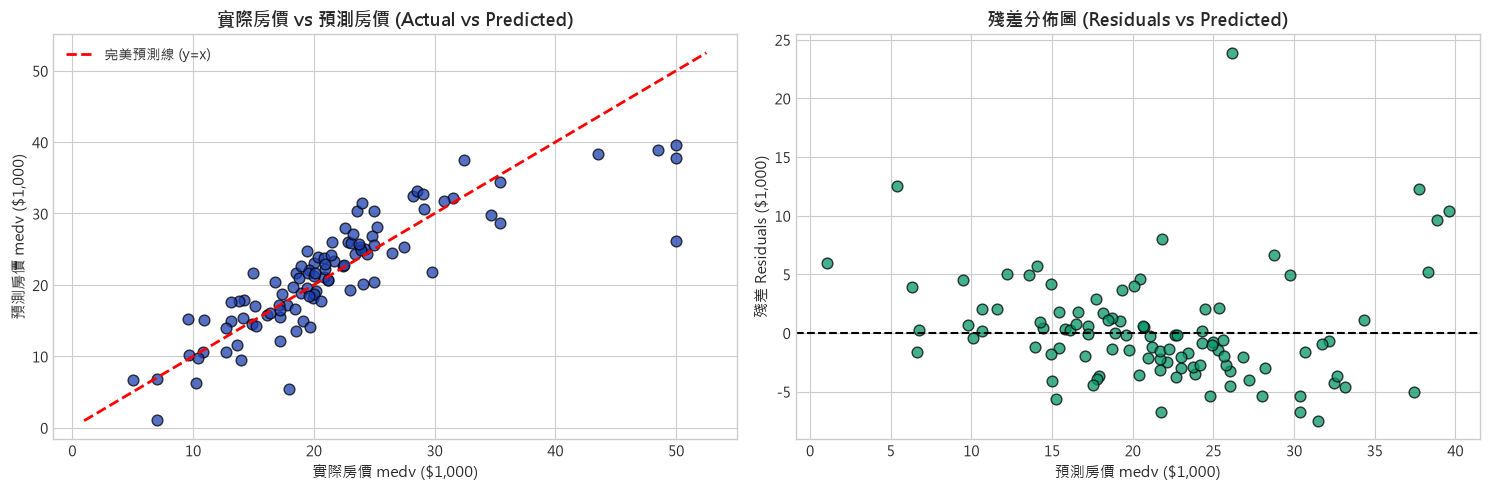

In [13]:
# 採用前向選取最佳模型
best_features = fwd_df.loc[best_fwd_idx, 'selected_features']
optimal_model = LinearRegression().fit(X_train[best_features], y_train)
y_pred_optimal = optimal_model.predict(X_test[best_features])
residuals = y_test - y_pred_optimal

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. 實際房價 vs 預測房價
axes[0].scatter(y_test, y_pred_optimal, color='#1e40af', s=60, alpha=0.75, edgecolors='black')
min_p = min(y_test.min(), y_pred_optimal.min()) * 0.95
max_p = max(y_test.max(), y_pred_optimal.max()) * 1.05
axes[0].plot([min_p, max_p], [min_p, max_p], 'r--', linewidth=2, label='完美預測線 (y=x)')
axes[0].set_title('實際房價 vs 預測房價 (Actual vs Predicted)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('實際房價 medv ($1,000)', fontsize=11)
axes[0].set_ylabel('預測房價 medv ($1,000)', fontsize=11)
axes[0].legend()

# 2. 殘差散布圖 (檢視同質變異數)
axes[1].scatter(y_pred_optimal, residuals, color='#059669', s=60, alpha=0.75, edgecolors='black')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('殘差分佈圖 (Residuals vs Predicted)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('預測房價 medv ($1,000)', fontsize=11)
axes[1].set_ylabel('殘差 Residuals ($1,000)', fontsize=11)

plt.tight_layout()
plt.show()


---
## Step 6: Deployment (模型序列化與應用推論)

### 6.1 模型持久化儲存 (Model Serialization)
將最佳波士頓房價預測模型儲存為序列化權重檔。

In [14]:
model_filename = 'boston_housing_best_model.pkl'
joblib.dump(optimal_model, model_filename)
print(f"✅ 最佳模型成功序列化儲存至: {model_filename}")


✅ 最佳模型成功序列化儲存至: boston_housing_best_model.pkl


### 6.2 部署推論函式 (Inference Pipeline)
撰寫即時估價推論示範，模擬兩組不同社區環境條件下的房價評估。

In [15]:
loaded_model = joblib.load(model_filename)

def predict_house_price(sample_dict):
    """
    輸入房屋周邊指標評估房價中位數
    """
    input_df = pd.DataFrame([sample_dict])[best_features]
    predicted_val = loaded_model.predict(input_df)[0]
    return predicted_val

# 範例情境比較
case_luxury = {
    'lstat': 4.5,   # 低收入人口僅 4.5%
    'rm': 7.5,      # 房間數高達 7.5 間
    'ptratio': 14.0,# 優質學區師生比 14
    'tax': 250,     # 稅率適中
    'crim': 0.05,
    'zn': 25.0,
    'indus': 3.0,
    'chas': 1,      # 河岸水岸景觀
    'nox': 0.45,
    'age': 20.0,
    'dis': 6.0,
    'rad': 3,
    'b': 390.0
}

case_affordable = {
    'lstat': 18.5,  # 低收入人口 18.5%
    'rm': 5.8,      # 房間數 5.8 間
    'ptratio': 20.0,# 師生比 20
    'tax': 666,
    'crim': 5.5,
    'zn': 0.0,
    'indus': 18.0,
    'chas': 0,
    'nox': 0.65,
    'age': 85.0,
    'dis': 2.0,
    'rad': 24,
    'b': 350.0
}

pred_luxury = predict_house_price(case_luxury)
pred_affordable = predict_house_price(case_affordable)

print("【房價預測推論展示】:")
print(f"🏡 社區 A (河岸高級住宅區/大戶型/優質學區):")
print(f"   👉 預估房價中位數: ${pred_luxury * 1000:,.2f} 美元 (medv = {pred_luxury:.2f})")
print(f"\n🏢 社區 B (高密度勞工社區/緊鄰商業區/高師生比):")
print(f"   👉 預估房價中位數: ${pred_affordable * 1000:,.2f} 美元 (medv = {pred_affordable:.2f})")


【房價預測推論展示】:
🏡 社區 A (河岸高級住宅區/大戶型/優質學區):
   👉 預估房價中位數: $36,340.57 美元 (medv = 36.34)

🏢 社區 B (高密度勞工社區/緊鄰商業區/高師生比):
   👉 預估房價中位數: $16,764.84 美元 (medv = 16.76)


---
## 7. 專案總結

### 🏆 核心成果回顧：
1. **完整遵循 CRISP-DM 六步驟**，從波士頓房地產業務目標出發，完成資料載入、前處理、建模、評估到部署閉環。
2. **實作並對比 5 種特徵選取方法**（Forward Selection、Backward Elimination、LassoCV、RFE、SelectKBest），跨越 Wrapper、Embedded 與 Filter 三大流派。
3. **成功繪製 1 至 13 特徵雙折線圖**，清楚展示特徵增加對測試集 RMSE 與 R² 的影響趨勢。
4. **發現共識關鍵特徵**：所有方法皆證實 `lstat`（低收入人口比例）、`rm`（每戶平均房間數）與 `ptratio`（師生比）為波士頓房價最核心的決定因子。
